## Teeth Disease Classification Project

#### Importing Modules

In [55]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import random 
from PIL import Image
import os
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import classification_report,confusion_matrix
import tensorflow as tf
import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,GlobalAveragePooling2D,Dense,Flatten,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau,ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

#### Setting Seed

In [56]:
SEED=42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

In [57]:
DATASET_DIR=r"D:\Teeth Classification\Teeth_Dataset"
TRAIN_DIR=os.path.join(DATASET_DIR,"Training")
VAL_DIR=os.path.join(DATASET_DIR,"Validation")
TEST_DIR=os.path.join(DATASET_DIR,"Testing")
IMG_SIZE=(256,256)
BATCH_SIZE=64
LABEL_MAP={
    "CaS":0,
    "CoS":1,
    "Gum":2,
    "MC":3,
    "OC":4,
    "OLP":5,
    "OT":6
}

#### Reading Files

In [58]:
image_paths=[]
labels=[]
splits=[]
data_splits=["Train","Val","Test"]
for split in data_splits:
    data_dir=TRAIN_DIR if split=="Train" else VAL_DIR if split=="Val" else TEST_DIR
    for class_name,class_label in LABEL_MAP.items():
        class_dir=os.path.join(data_dir,class_name)
        for file in os.listdir(class_dir):
            file_path=os.path.join(class_dir,file)
            image_paths.append(file_path)
            labels.append(class_label)
            splits.append(split)
print(f"Sample Image path: {image_paths[4]}, label: {labels[4]} and split: {splits[4]}")

Sample Image path: D:\Teeth Classification\Teeth_Dataset\Training\CaS\a_100_0_6127.jpg, label: 0 and split: Train


#### Creating DataFrame

In [59]:
df=pd.DataFrame({
    "image":image_paths,
    "label":labels,
    "split":splits
})
df.head()

,image,label,split
0,D:\Teeth Classification\Teeth_Dataset\Training...,0,Train
1,D:\Teeth Classification\Teeth_Dataset\Training...,0,Train
2,D:\Teeth Classification\Teeth_Dataset\Training...,0,Train
3,D:\Teeth Classification\Teeth_Dataset\Training...,0,Train
4,D:\Teeth Classification\Teeth_Dataset\Training...,0,Train


In [60]:
print("Total Number of images:",len(df),"images.")

Total Number of images: 5143 images.


#### Shuffling DataFrame

In [61]:
df=df.sample(frac=1,random_state=SEED)
df.head()

,image,label,split
4169,D:\Teeth Classification\Teeth_Dataset\Testing\...,0,Test
4151,D:\Teeth Classification\Teeth_Dataset\Testing\...,0,Test
3066,D:\Teeth Classification\Teeth_Dataset\Training...,6,Train
4133,D:\Teeth Classification\Teeth_Dataset\Testing\...,0,Test
626,D:\Teeth Classification\Teeth_Dataset\Training...,1,Train


#### Visualizing Random Samples

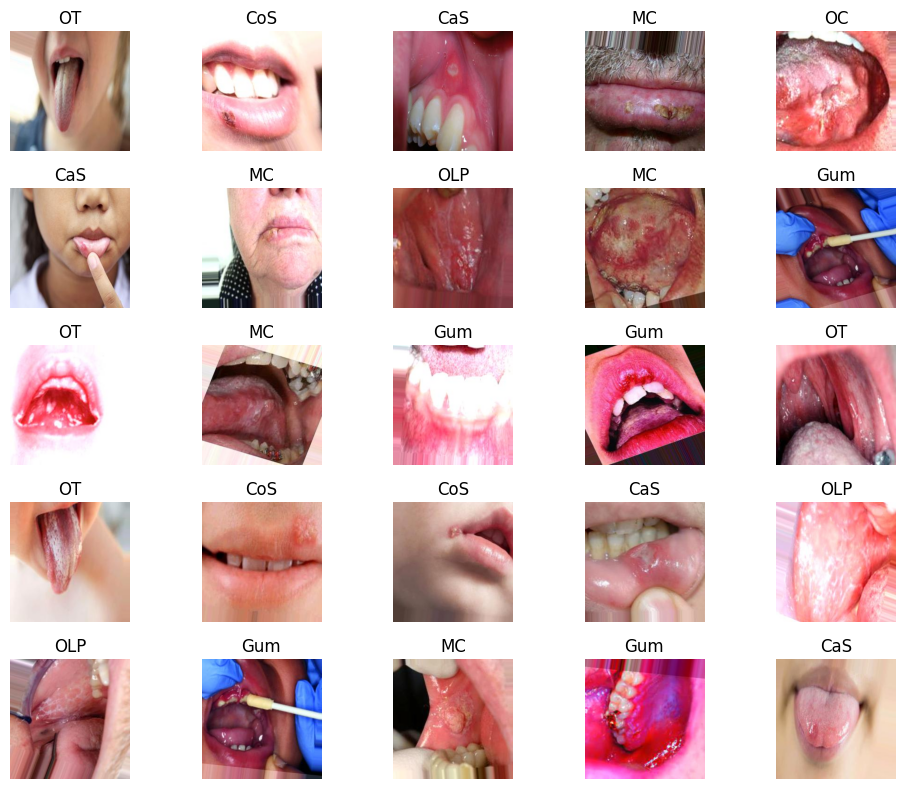

In [62]:
plt.figure(figsize=(10,8))
sample_df=df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    image_label=row['label']
    plt.subplot(5,5,i+1)
    img=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(img)
    label = {v: k for k, v in LABEL_MAP.items()}[image_label]
    plt.title(label)
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Checking Class Distribution

In [63]:
df['label'].value_counts()

label
3    900
5    900
0    800
1    748
6    655
2    600
4    540
Name: count, dtype: int64

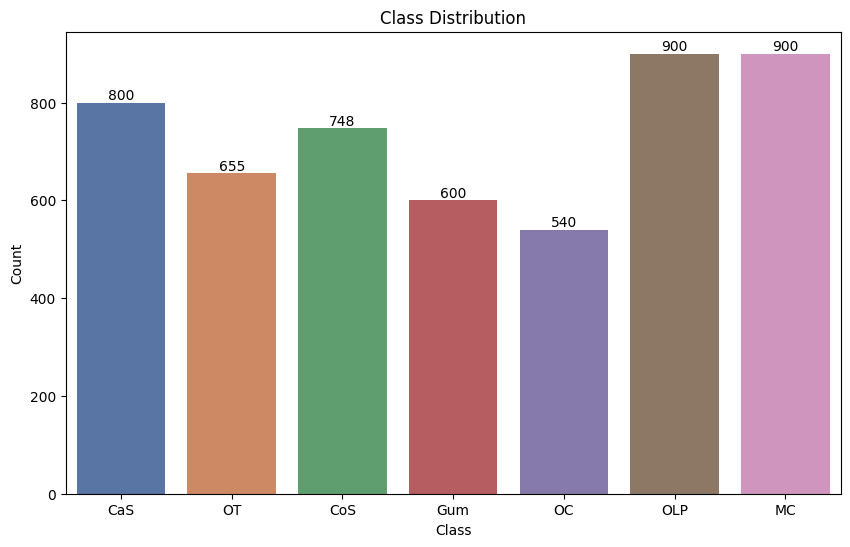

In [64]:
plt.figure(figsize=(10,6))
ax=sns.countplot(
    x=df['label'].map({v:k for k,v in LABEL_MAP.items()}),
    hue=df['label'].map({v:k for k,v in LABEL_MAP.items()}),
    palette="deep",
    legend=False
)
for container in ax.containers:
    ax.bar_label(container)
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.show()

#### Creating Train, Test, Val DataFrames

In [65]:
train_df=df[df['split']=="Train"]
val_df=df[df['split']=="Val"]
test_df=df[df['split']=="Test"]
print("Train Size: ",len(train_df))
print("Validation Size: ",len(val_df))
print("Test Size: ",len(test_df))

Train Size:  3087
Validation Size:  1028
Test Size:  1028


#### Fixing Datatypes

In [66]:
train_df['label']=train_df['label'].astype('str')
test_df['label']=test_df['label'].astype('str')
val_df['label']=val_df['label'].astype('str')

#### Creating Data Generators

In [67]:
train_data_gen=ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    #shear_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'    
)

In [68]:
val_test_data_gen=ImageDataGenerator(
    preprocessing_function=preprocess_input
)

#### Creating Iterators

In [69]:
train_iterator=train_data_gen.flow_from_dataframe(
    train_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

Found 3087 validated image filenames belonging to 7 classes.


In [70]:
val_iterator=val_test_data_gen.flow_from_dataframe(
    val_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

Found 1028 validated image filenames belonging to 7 classes.


In [71]:
test_iterator=val_test_data_gen.flow_from_dataframe(
    test_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

Found 1028 validated image filenames belonging to 7 classes.


#### Creating Model

In [72]:
base_model=EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE,3)
)
base_model.trainable=False
model=Sequential([
    base_model,
    Flatten(),
    Dense(64,activation='relu'),
    Dropout(0.2),
    Dense(len(LABEL_MAP),activation='softmax')
])

In [73]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 81920)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     5,242,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,292,970 (35.45 MB)

 Trainable params: 5,243,399 (20.00 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [74]:
opt=keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=opt,loss='categorical_crossentropy',metrics=['accuracy'])

In [75]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    patience=3,
    factor=0.2,
    min_lr=1e-5
)

In [76]:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

In [77]:
checkpoint=ModelCheckpoint(
    "best_model_transfer_learning.keras",
    monitor='val_loss',
    save_best_only=True
)

In [78]:
history=model.fit(train_iterator,validation_data=val_iterator,epochs=15,callbacks=[lr_scheduler,early_stop,checkpoint])

Epoch 1/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.4911 - loss: 1.6408 - val_accuracy: 0.6654 - val_loss: 0.8881 - learning_rate: 0.0010
Epoch 2/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.6676 - loss: 0.8780 - val_accuracy: 0.7947 - val_loss: 0.5999 - learning_rate: 0.0010
Epoch 3/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.7451 - loss: 0.6647 - val_accuracy: 0.8502 - val_loss: 0.4206 - learning_rate: 0.0010
Epoch 4/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.8154 - loss: 0.4786 - val_accuracy: 0.8959 - val_loss: 0.3056 - learning_rate: 0.0010
Epoch 5/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.8367 - loss: 0.4386 - val_accuracy: 0.9241 - val_loss: 0.2579 - learning_rate: 0.0010
Epoch 6/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.8682 - loss: 0.3650 - val_accuracy: 0.9436 - val_loss: 0.1684 - learning_rate: 0.0010
Epoch 7/15
49/49 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.8782 - loss: 0.3323 - val_accu

#### Evaluating Model

In [79]:
test_results=model.evaluate(test_iterator,return_dict=True)
print(test_results)

17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9698 - loss: 0.1032
{'accuracy': 0.9698443412780762, 'loss': 0.1031758263707161}


#### Accuracies and Losses Graphs

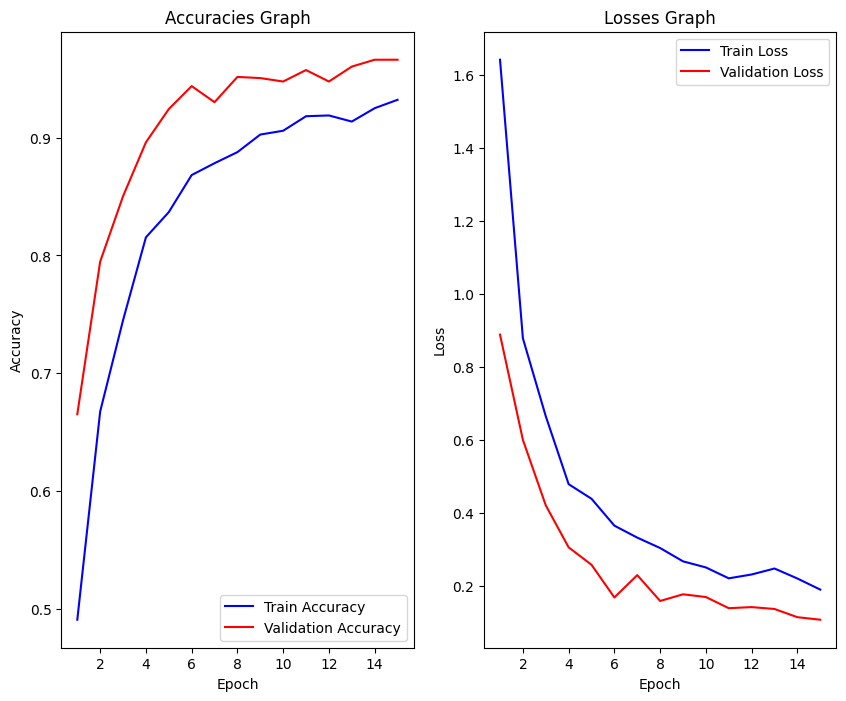

In [80]:
plt.figure(figsize=(10,8))
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
train_loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(train_acc)+1)
plt.subplot(1,2,1)
plt.plot(epochs,train_acc,'b',label="Train Accuracy")
plt.plot(epochs,val_acc,'r',label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracies Graph")
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs,train_loss,'b',label="Train Loss")
plt.plot(epochs,val_loss,'r',label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Losses Graph")
plt.legend()
plt.show()

#### Visualizing Sample Images

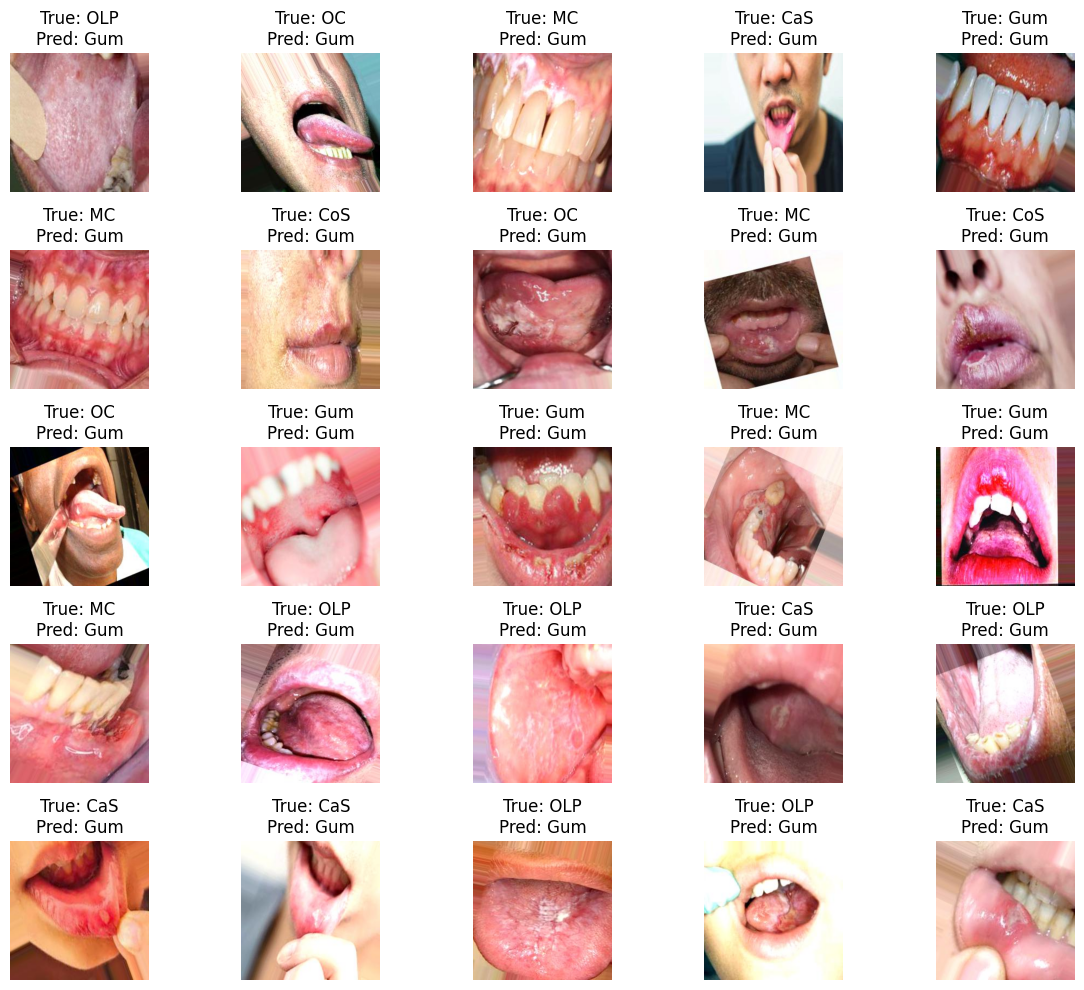

In [81]:

plt.figure(figsize=(12, 10))

sample_df = test_df.sample(25, random_state=SEED)

for i, (_, row) in enumerate(sample_df.iterrows()):
    image_path = row['image']
    true_label = int(row['label'])

    plt.subplot(5, 5, i + 1)

    img = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(img)

    img = np.array(img, dtype=np.float32) / 255.0
    img = np.expand_dims(img, axis=0)

    pred_probs = model.predict(img, verbose=0)[0]
    pred_label = np.argmax(pred_probs)

    true_name = {v: k for k, v in LABEL_MAP.items()}[true_label]
    pred_name = {v: k for k, v in LABEL_MAP.items()}[pred_label]

    plt.title(f"True: {true_name}\nPred: {pred_name}")
    plt.axis('off')

plt.tight_layout()
plt.show()


#### Confusion Matrix

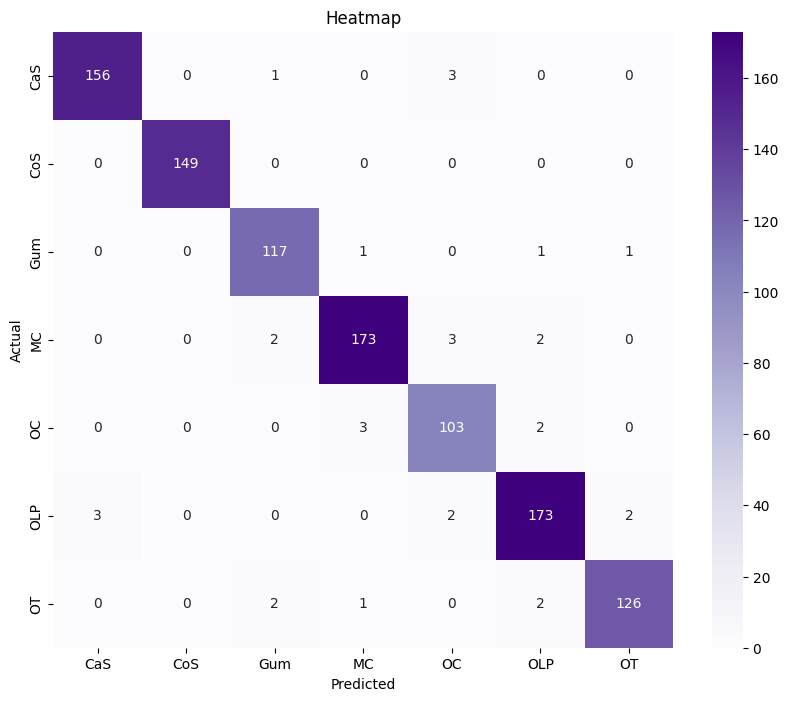

In [82]:
plt.figure(figsize=(10,8))
y_true=test_iterator.classes
y_pred_prob=model.predict(test_iterator,verbose=0)
y_pred=np.argmax(y_pred_prob,axis=1)
# np.argmax() returns the index (position) of the largest value in an array.
# In multiclass classification, it selects the class with the highest predicted probability
# ex: arr = [0.05, 0.10, 0.65, 0.05, 0.05, 0.05, 0.05] so np.argmax(arr) returns 2 bec 2 is index of highest value (0.65)
cm=confusion_matrix(y_true,y_pred,labels=list(LABEL_MAP.values()))
sns.heatmap(cm,annot=True,cmap='Purples',fmt='d',xticklabels=list(LABEL_MAP.keys()),yticklabels=list(LABEL_MAP.keys()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heatmap")
plt.show()

#### Classification Report

In [83]:
print(classification_report(y_true,y_pred,labels=list(LABEL_MAP.values()),target_names=list(LABEL_MAP.keys())))

              precision    recall  f1-score   support

         CaS       0.98      0.97      0.98       160
         CoS       1.00      1.00      1.00       149
         Gum       0.96      0.97      0.97       120
          MC       0.97      0.96      0.97       180
          OC       0.93      0.95      0.94       108
         OLP       0.96      0.96      0.96       180
          OT       0.98      0.96      0.97       131

    accuracy                           0.97      1028
   macro avg       0.97      0.97      0.97      1028
weighted avg       0.97      0.97      0.97      1028

